In [27]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [28]:
#Generate Train/Dev/Test splits from annotated Sorani file
import random
import os

# Set seed for reproducibility
random.seed(42)

# Paths
BASE_PATH_ANNOTATED = "/content/drive/MyDrive/Kurdish_NER_Project/data/annotated/"
BASE_PATH_SPLITS = "/content/drive/MyDrive/Kurdish_NER_Project/data/splits/"
SORANI_FILE = "ner_sorani.txt"

ANNOTATED_FILE = os.path.join(BASE_PATH_ANNOTATED, SORANI_FILE)

print("Loading:", ANNOTATED_FILE)

# Load annotated sentences
sorani_dataset = []
current_sentence = []

with open(ANNOTATED_FILE, "r", encoding="utf-8") as f:
    for line in f:
        line = line.strip()
        if not line or line.startswith("article"):
            if current_sentence:
                sorani_dataset.append(current_sentence)
                current_sentence = []
            continue
        parts = line.split("\t")
        if len(parts) == 2:
            current_sentence.append(parts)
# Append last sentence
if current_sentence:
    sorani_dataset.append(current_sentence)

print("Total sentences loaded:", len(sorani_dataset))

# Shuffle and split 80/10/10
random.shuffle(sorani_dataset)
total = len(sorani_dataset)
train_end = int(total * 0.8)
dev_end = int(total * 0.9)

train_data = sorani_dataset[:train_end]
dev_data = sorani_dataset[train_end:dev_end]
test_data = sorani_dataset[dev_end:]

print("Train:", len(train_data))
print("Dev:  ", len(dev_data))
print("Test: ", len(test_data))

# Save splits
os.makedirs(BASE_PATH_SPLITS, exist_ok=True)

def save_split(data, filename):
    path = os.path.join(BASE_PATH_SPLITS, filename)
    with open(path, "w", encoding="utf-8") as f:
        for sentence in data:
            for token, tag in sentence:
                f.write(f"{token}\t{tag}\n")
            f.write("\n")
    print("Saved:", path)

save_split(train_data, "train_sorani.txt")
save_split(dev_data, "dev_sorani.txt")
save_split(test_data, "test_sorani.txt")

print("\n✅ Splits created successfully!")


Loading: /content/drive/MyDrive/Kurdish_NER_Project/data/annotated/ner_sorani.txt
Total sentences loaded: 62
Train: 49
Dev:   6
Test:  7
Saved: /content/drive/MyDrive/Kurdish_NER_Project/data/splits/train_sorani.txt
Saved: /content/drive/MyDrive/Kurdish_NER_Project/data/splits/dev_sorani.txt
Saved: /content/drive/MyDrive/Kurdish_NER_Project/data/splits/test_sorani.txt

✅ Splits created successfully!


In [29]:
!pip install sklearn-crfsuite


In [30]:
#Load splits and check sentences

import os

def load_conll_file(filepath):
    """Load CoNLL-style file into list of sentences (token, tag)"""
    sentences = []
    sentence = []
    with open(filepath, "r", encoding="utf-8") as f:
        for line in f:
            line = line.strip()
            if not line:
                if sentence:
                    sentences.append(sentence)
                    sentence = []
                continue
            parts = line.split("\t")
            if len(parts) == 2:
                sentence.append((parts[0], parts[1]))
    if sentence:
        sentences.append(sentence)
    return sentences

BASE_PATH_SPLITS = "/content/drive/MyDrive/Kurdish_NER_Project/data/splits/"

train_sorani = load_conll_file(os.path.join(BASE_PATH_SPLITS, "train_sorani.txt"))
dev_sorani = load_conll_file(os.path.join(BASE_PATH_SPLITS, "dev_sorani.txt"))
test_sorani = load_conll_file(os.path.join(BASE_PATH_SPLITS, "test_sorani.txt"))

print("Train sentences:", len(train_sorani))
print("Dev sentences:", len(dev_sorani))
print("Test sentences:", len(test_sorani))



Train sentences: 49
Dev sentences: 6
Test sentences: 7


In [31]:
#Feature extraction for CRF
def word2features(sent, i):
    word = sent[i][0]
    features = {
        'bias': 1.0,
        'word.lower()': word.lower(),
        'word[-3:]': word[-3:],
        'word[-2:]': word[-2:],
        'word.isupper()': word.isupper(),
        'word.istitle()': word.istitle(),
        'word.isdigit()': word.isdigit(),
    }
    if i > 0:
        prev_word = sent[i-1][0]
        features.update({
            '-1:word.lower()': prev_word.lower(),
            '-1:word.istitle()': prev_word.istitle(),
            '-1:word.isupper()': prev_word.isupper(),
        })
    else:
        features['BOS'] = True

    if i < len(sent)-1:
        next_word = sent[i+1][0]
        features.update({
            '+1:word.lower()': next_word.lower(),
            '+1:word.istitle()': next_word.istitle(),
            '+1:word.isupper()': next_word.isupper(),
        })
    else:
        features['EOS'] = True

    return features

def sent2features(sent):
    return [word2features(sent, i) for i in range(len(sent))]

def sent2labels(sent):
    return [label for token, label in sent]

def sent2tokens(sent):
    return [token for token, label in sent]


In [32]:
#Prepare train/dev/test feature sets
# Create features and labels
X_train = [sent2features(s) for s in train_sorani]
y_train = [sent2labels(s) for s in train_sorani]

X_dev = [sent2features(s) for s in dev_sorani]
y_dev = [sent2labels(s) for s in dev_sorani]

X_test = [sent2features(s) for s in test_sorani]
y_test = [sent2labels(s) for s in test_sorani]


In [33]:
#Train CRF
import sklearn_crfsuite
from sklearn_crfsuite import metrics

crf = sklearn_crfsuite.CRF(
    algorithm='lbfgs',
    c1=0.1,
    c2=0.1,
    max_iterations=100,
    all_possible_transitions=True
)

crf.fit(X_train, y_train)
print("✅ CRF trained!")
print("CRF classes:", crf.classes_)


✅ CRF trained!
CRF classes: ['O', 'B-ORG', 'I-ORG', 'B-DATE', 'I-DATE', 'B-PER', 'I-PER', 'B-LOC', 'I-LOC']


In [34]:
#Evaluate CRF
labels = list(crf.classes_)
labels.remove('O')  # often we ignore 'O' in evaluation

# DEV evaluation
y_pred_dev = crf.predict(X_dev)
print("=== DEV EVALUATION ===")
print(metrics.flat_classification_report(y_dev, y_pred_dev, labels=labels, digits=3))

# TEST evaluation
y_pred_test = crf.predict(X_test)
print("=== TEST EVALUATION ===")
print(metrics.flat_classification_report(y_test, y_pred_test, labels=labels, digits=3))


=== DEV EVALUATION ===
              precision    recall  f1-score   support

       B-ORG      0.979     0.723     0.832        65
       I-ORG      0.931     0.771     0.844        35
      B-DATE      0.958     0.885     0.920        26
      I-DATE      0.889     0.941     0.914        34
       B-PER      0.914     0.679     0.779        78
       I-PER      0.905     0.704     0.792        27
       B-LOC      0.957     0.863     0.907       153
       I-LOC      1.000     0.800     0.889        15

   micro avg      0.943     0.797     0.864       433
   macro avg      0.942     0.796     0.860       433
weighted avg      0.943     0.797     0.861       433

=== TEST EVALUATION ===
              precision    recall  f1-score   support

       B-ORG      0.931     0.771     0.844        35
       I-ORG      0.930     0.851     0.889        47
      B-DATE      1.000     0.900     0.947        20
      I-DATE      1.000     0.963     0.981        27
       B-PER      0.949     0.7

In [35]:
#Save model
import pickle

model_path = "/content/drive/MyDrive/Kurdish_NER_Project/models/model_sorani.pkl"
with open(model_path, "wb") as f:
    pickle.dump(crf, f)

print("✅ Model saved at:", model_path)


✅ Model saved at: /content/drive/MyDrive/Kurdish_NER_Project/models/model_sorani.pkl


In [36]:
def load_annotated_file(file_path):
    """Load annotated file and return list of sentences (token, tag)"""
    sentences = []
    current_sent = []

    with open(file_path, "r", encoding="utf-8") as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith("article"):
                if current_sent:
                    sentences.append(current_sent)
                    current_sent = []
                continue

            # Use rsplit to ensure only last tab separates token and tag
            if '\t' in line:
                token, tag = line.rsplit('\t', 1)
                current_sent.append((token, tag))
            else:
                print(f"⚠️ Skipping malformed line: {line}")

    if current_sent:
        sentences.append(current_sent)

    return sentences

annotated_file = "/content/drive/MyDrive/Kurdish_NER_Project/data/annotated/ner_sorani.txt"
sorani_dataset = load_annotated_file(annotated_file)
print("Total sentences loaded:", len(sorani_dataset))


Total sentences loaded: 62


In [37]:
all_labels = set([tag for sent in sorani_dataset for token, tag in sent])
print("Labels found in dataset:", all_labels)


Labels found in dataset: {'O', 'B-DATE', 'B-PER', 'I-LOC', 'I-DATE', 'I-PER', 'B-ORG', 'B-LOC', 'I-ORG'}


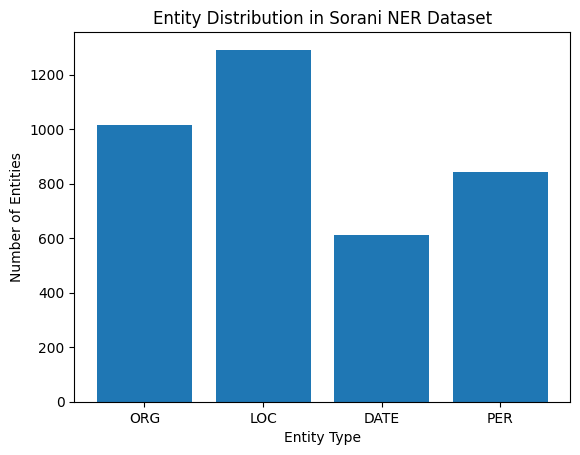

In [38]:
#This shows how many entities of each type exist in your dataset.
import matplotlib.pyplot as plt
from collections import Counter

# Count entity labels from annotated file
annotated_file = "/content/drive/MyDrive/Kurdish_NER_Project/data/annotated/ner_sorani.txt"

labels = []
with open(annotated_file, "r", encoding="utf-8") as f:
    for line in f:
        line = line.strip()
        if not line or line.startswith("article"):
            continue
        token, tag = line.split("\t")
        if tag != "O":
            labels.append(tag.split("-")[1])  # PER, ORG, LOC, DATE

counter = Counter(labels)

plt.figure()
plt.bar(counter.keys(), counter.values())
plt.title("Entity Distribution in Sorani NER Dataset")
plt.xlabel("Entity Type")
plt.ylabel("Number of Entities")
plt.show()


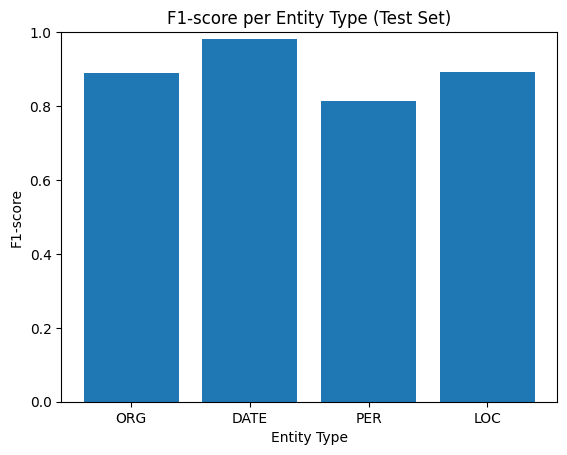

In [39]:
#F1-score per Entity (TEST)
#Use TEST evaluation results.
entities = ["ORG", "DATE", "PER", "LOC"]
f1_scores = [0.889, 0.981, 0.813, 0.892]  # from your TEST output

plt.figure()
plt.bar(entities, f1_scores)
plt.title("F1-score per Entity Type (Test Set)")
plt.xlabel("Entity Type")
plt.ylabel("F1-score")
plt.ylim(0,1)
plt.show()


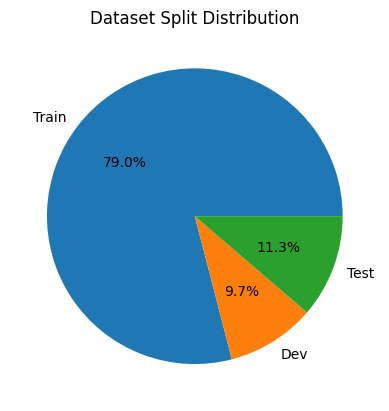

In [40]:
#Dataset Split Sizes
splits = ["Train", "Dev", "Test"]
sizes = [49, 6, 7]

plt.figure()
plt.pie(sizes, labels=splits, autopct='%1.1f%%')
plt.title("Dataset Split Distribution")
plt.show()
